In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/amwmich/spotify-dataset-fiks/spotify_songs.csv


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

In [5]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/amwmich/spotify-dataset-fiks/spotify_songs.csv


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv('/kaggle/input/datasets/amwmich/spotify-dataset-fiks/spotify_songs.csv')

In [7]:
print("Dimensi dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())
print("\nTipe data tiap kolom:")
display(df.dtypes.to_frame(name="Data type"))
display(df.head())

Dimensi dataset: (32833, 23)

Nama kolom:
['track_id', 'track_name', 'track_artist', 'track_popularity', 'track_album_id', 'track_album_name', 'track_album_release_date', 'playlist_name', 'playlist_id', 'playlist_genre', 'playlist_subgenre', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']

Tipe data tiap kolom:


,Data type
track_id,object
track_name,object
track_artist,object
track_popularity,int64
track_album_id,object
track_album_name,object
track_album_release_date,object
playlist_name,object
playlist_id,object
playlist_genre,object


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


In [7]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2)
})
display(missing_summary)

,missing_count,missing_percentage
track_id,0,0.00
track_name,5,0.02
track_artist,5,0.02
track_popularity,0,0.00
track_album_id,0,0.00
track_album_name,5,0.02
track_album_release_date,0,0.00
playlist_name,0,0.00
playlist_id,0,0.00
playlist_genre,0,0.00


In [8]:
missing_rows = df.loc[df.isna().any(axis=1)]

print("Jumlah baris dengan minimal satu missing value:", len(missing_rows))
display(missing_rows)

print("\nMissing variables by row")
for idx, row in missing_rows.iterrows():
    print(idx, row.index[row.isna()].tolist())

Jumlah baris dengan minimal satu missing value: 5


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
8151,69gRFGOWY9OMpFJgFol1u0,NaN,NaN,0,717UG2du6utFe7CdmpuUe3,NaN,2012-01-05,HIP&HOP,5DyJsJZOpMJh34WvUrQzMV,rap,...,6,-7.635,1,0.1760,0.0410,0.00000,0.1160,0.649,95.999,282707
9282,5cjecvX0CmC9gK0Laf5EMQ,NaN,NaN,0,3luHJEPw434tvNbme3SP8M,NaN,2017-12-01,GANGSTA Rap,5GA8GDo7RQC3JEanT81B3g,rap,...,11,-5.364,0,0.3190,0.0534,0.00000,0.5530,0.191,146.153,202235
9283,5TTzhRSWQS4Yu8xTgAuq6D,NaN,NaN,0,3luHJEPw434tvNbme3SP8M,NaN,2017-12-01,GANGSTA Rap,5GA8GDo7RQC3JEanT81B3g,rap,...,10,-5.907,0,0.3070,0.0963,0.00000,0.0888,0.505,86.839,206465
19568,3VKFip3OdAvv4OfNTgFWeQ,NaN,NaN,0,717UG2du6utFe7CdmpuUe3,NaN,2012-01-05,Reggaeton viejito🔥,0si5tw70PIgPkY1Eva6V8f,latin,...,11,-6.075,0,0.0366,0.0606,0.00653,0.1030,0.726,97.017,252773
19811,69gRFGOWY9OMpFJgFol1u0,NaN,NaN,0,717UG2du6utFe7CdmpuUe3,NaN,2012-01-05,latin hip hop,3nH8aytdqNeRbcRCg3dw9q,latin,...,6,-7.635,1,0.1760,0.0410,0.00000,0.1160,0.649,95.999,282707



Missing variables by row
8151 ['track_name', 'track_artist', 'track_album_name']
9282 ['track_name', 'track_artist', 'track_album_name']
9283 ['track_name', 'track_artist', 'track_album_name']
19568 ['track_name', 'track_artist', 'track_album_name']
19811 ['track_name', 'track_artist', 'track_album_name']


In [9]:
display(df.describe(include=[np.number]).T)

,count,mean,std,min,25%,50%,75%,max
track_popularity,32833.0,42.477081,24.984074,0.000000,24.0000,45.000000,62.00000,100.000
danceability,32833.0,0.654850,0.145085,0.000000,0.5630,0.672000,0.76100,0.983
energy,32833.0,0.698619,0.180910,0.000175,0.5810,0.721000,0.84000,1.000
key,32833.0,5.374471,3.611657,0.000000,2.0000,6.000000,9.00000,11.000
loudness,32833.0,-6.719499,2.988436,-46.448000,-8.1710,-6.166000,-4.64500,1.275
mode,32833.0,0.565711,0.495671,0.000000,0.0000,1.000000,1.00000,1.000
speechiness,32833.0,0.107068,0.101314,0.000000,0.0410,0.062500,0.13200,0.918
acousticness,32833.0,0.175334,0.219633,0.000000,0.0151,0.080400,0.25500,0.994
instrumentalness,32833.0,0.084747,0.224230,0.000000,0.0000,0.000016,0.00483,0.994
liveness,32833.0,0.190176,0.154317,0.000000,0.0927,0.127000,0.24800,0.996


In [10]:
total_missing = df.isnull().sum().sum()
total_data = df.shape[0] * df.shape[1]

print("Total missing values:", total_missing)
print("Persentase missing values:", round(total_missing / total_data * 100, 2), "%")

Total missing values: 15
Persentase missing values: 0.0 %


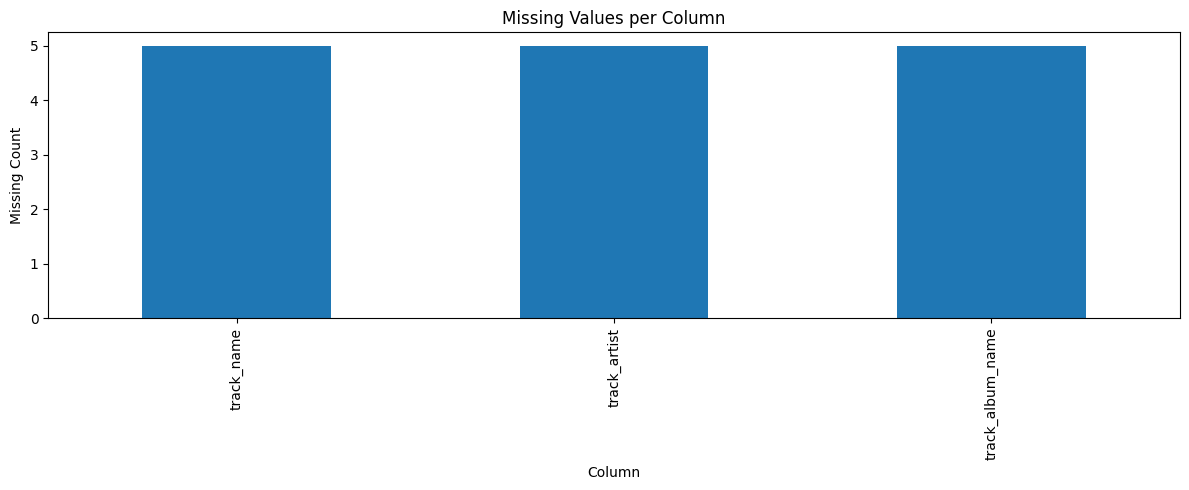

In [11]:
missing_column = df.isnull().sum()
missing_column = missing_column[missing_column > 0]

plt.figure(figsize=(12, 5))
missing_column.plot(kind='bar')

plt.title('Missing Values per Column')
plt.xlabel('Column')
plt.ylabel('Missing Count')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [16]:
exact_duplicate = df.duplicated().sum()

print("Jumlah exact duplicates:", exact_duplicate)
print("Duplicated Track ID Values:")
display(df[df.duplicated("track_id", keep=False)].sort_values("track_id"))
print("Duplicated Track Album ID Values:")
display(df[df.duplicated("track_album_id", keep=False)].sort_values("track_album_id"))
print("Duplicated Playlist ID Values:")
display(df[df.duplicated("playlist_id", keep=False)].sort_values("playlist_id"))

Jumlah exact duplicates: 0
Duplicated Track ID Values:


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
32084,00Gu3RMpDW2vO9PjlMVFDL,Hide Away (feat. Envy Monroe),Blasterjaxx,42,5pqG85igfoeWcCDIsSi9x7,Hide Away (feat. Envy Monroe),2019-06-21,Epic Bass Drops | Best House Mixes,4IS7o1utOzhimFEFnj9gmu,edm,...,10,-4.894,1,0.0421,0.0249,0.000000,0.3610,0.134,130.001,188000
28696,00Gu3RMpDW2vO9PjlMVFDL,Hide Away (feat. Envy Monroe),Blasterjaxx,42,5pqG85igfoeWcCDIsSi9x7,Hide Away (feat. Envy Monroe),2019-06-21,Big Room EDM - by Spinnin' Records,7xWdFCrU5Gka6qp1ODrSdK,edm,...,10,-4.894,1,0.0421,0.0249,0.000000,0.3610,0.134,130.001,188000
23850,00QyLmjxaSEE8qIZQjBXBj,We Own It (Fast & Furious),2 Chainz,59,1jg2UPoSAr7CDPsEXcabo1,Fast & Furious 6,2013-01-01,Today's Hits (Clean),7ENISpOJhocpMJVcGb0qcT,r&b,...,8,-4.573,1,0.4080,0.0521,0.000000,0.0568,0.552,171.966,227893
28968,00QyLmjxaSEE8qIZQjBXBj,We Own It (Fast & Furious),2 Chainz,59,1jg2UPoSAr7CDPsEXcabo1,Fast & Furious 6,2013-01-01,Locker Room,37i9dQZF1DX8SaiEt4OVJw,edm,...,8,-4.573,1,0.4080,0.0521,0.000000,0.0568,0.552,171.966,227893
9387,00QyLmjxaSEE8qIZQjBXBj,We Own It (Fast & Furious),2 Chainz,59,1jg2UPoSAr7CDPsEXcabo1,Fast & Furious 6,2013-01-01,RAP Gangsta,1Z1gW89x4MSBjkvVjGg7DQ,rap,...,8,-4.573,1,0.4080,0.0521,0.000000,0.0568,0.552,171.966,227893
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32074,7zHrHnVSQwI95FGHewXDl8,Do Bad Well (feat. Nevve),KSHMR,62,3BAigRfKg2iyWJuWlZCZZQ,Do Bad Well (feat. Nevve),2019-10-11,Epic Bass Drops | Best House Mixes,4IS7o1utOzhimFEFnj9gmu,edm,...,5,-4.755,1,0.1130,0.0512,0.000315,0.2340,0.415,127.964,204375
28932,7zHrHnVSQwI95FGHewXDl8,Do Bad Well (feat. Nevve),KSHMR,62,3BAigRfKg2iyWJuWlZCZZQ,Do Bad Well (feat. Nevve),2019-10-11,Bounce United,08QTrfsYYouffgnPjmllAQ,edm,...,5,-4.755,1,0.1130,0.0512,0.000315,0.2340,0.415,127.964,204375
2850,7zsXy7vlHdItvUSH8EwQss,Cold Water,Major Lazer,69,3Kmo85mapQ2wTaCAHBkKsK,Cold Water,2016-07-22,ElectroPop 2020,4frhr6RQM2fMOm2mpvOVo6,pop,...,6,-5.092,0,0.0432,0.0736,0.000000,0.1560,0.501,92.943,185360
30939,7zsXy7vlHdItvUSH8EwQss,Cold Water,Major Lazer,69,3Kmo85mapQ2wTaCAHBkKsK,Cold Water,2016-07-22,EDM/POP,6gHk5RFrnALbDNJdaXKivi,edm,...,6,-5.092,0,0.0432,0.0736,0.000000,0.1560,0.501,92.943,185360


Duplicated Track Album ID Values:


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
9655,7o7rrKyfqGo5xw318JNFUb,Only You (feat. Notorious B.I.G. and Mase) - G...,112,44,006AgHXrEw13oyg0D8evRa,Bad Boy Greatest Hits Vol. 1,1998,90s Gangsta Rap / Top Hip-hop Classics,0C2zyPdlkbWHrwVg9gqNdU,rap,...,8,-6.392,1,0.0508,0.016200,0.000000,0.0569,0.779,95.952,290040
25103,7o7rrKyfqGo5xw318JNFUb,Only You (feat. Notorious B.I.G. and Mase) - G...,112,44,006AgHXrEw13oyg0D8evRa,Bad Boy Greatest Hits Vol. 1,1998,R&B 80's/90's/00's,2Ey63yNQeC9Yto7JwX9BGJ,r&b,...,8,-6.392,1,0.0508,0.016200,0.000000,0.0569,0.779,95.952,290040
11244,4paAidoE8VAemwU4jgCc6l,all my friends,21 Savage,72,007DWn799UWvfY1wwZeENR,i am > i was,2018-12-21,Trap Americana,7tkgK1tm9hYkWp7EFyOcAr,rap,...,0,-4.513,1,0.0422,0.171000,0.000001,0.1180,0.206,130.090,211785
11218,2t8yVaLvJ0RenpXUIAC52d,a lot,21 Savage,81,007DWn799UWvfY1wwZeENR,i am > i was,2018-12-21,Trap Americana,7tkgK1tm9hYkWp7EFyOcAr,rap,...,1,-7.643,1,0.0860,0.039500,0.001250,0.3420,0.274,145.972,288624
8985,2t8yVaLvJ0RenpXUIAC52d,a lot,21 Savage,81,007DWn799UWvfY1wwZeENR,i am > i was,2018-12-21,GTA San Andreas Radio Los Santos,6m0BqpJfSP2m5xCOFjDRHw,rap,...,1,-7.643,1,0.0860,0.039500,0.001250,0.3420,0.274,145.972,288624
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24092,57ysLbmFhxX9WL9e5QTAmz,The Way That You Love Me,Paula Abdul,36,7zduRJgS6v79QmNUhKGozu,Forever Your Girl,1988-01-01,New Jack Swing,3ykXidKLz1eYPvuGoFlD1e,r&b,...,1,-8.297,1,0.0729,0.093200,0.003430,0.0825,0.886,119.969,322667
25067,1xvXZfgG3S62hoXJAoCha4,Glow,Kelis,34,7zesXMFikT4DdgkklIk3Jz,Tasty,2003-01-01,R&B 80's/90's/00's,2Ey63yNQeC9Yto7JwX9BGJ,r&b,...,0,-6.503,1,0.0620,0.014900,0.000639,0.0743,0.640,91.451,240027
25058,3ixyQ0IdbbDaYOyodp6hvr,Attention,Kelis,26,7zesXMFikT4DdgkklIk3Jz,Tasty,2003-01-01,R&B 80's/90's/00's,2Ey63yNQeC9Yto7JwX9BGJ,r&b,...,2,-4.606,1,0.0378,0.000398,0.009870,0.1130,0.522,96.843,204333
9647,1YQ7BbJR8HqAolfprvxGKu,Notorious B.I.G. (feat. Lil' Kim & Puff Daddy)...,The Notorious B.I.G.,56,7zg9ZSOQtYLjWnvSawflg6,Born Again,1999,90s Gangsta Rap / Top Hip-hop Classics,0C2zyPdlkbWHrwVg9gqNdU,rap,...,1,-2.372,0,0.2720,0.053100,0.000000,0.2140,0.824,101.350,191600


Duplicated Playlist ID Values:


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
7921,2MYl0er3UZ1RlKwRb5LODh,A.D.H.D,Kendrick Lamar,15,13WjgUEEAQp0d9JqojlWp1,Section.80,2011-07-02,Hip-Hop 'n RnB,0275i1VNfBnsNbPl0QIBpG,rap,...,9,-6.883,1,0.2400,0.3300,0.000000,0.1080,0.582,157.740,215509
7961,0Bpkq4z0VfjkO7kUME8gks,Forever,Drake,2,0A6B6kaJ0asKZlbvKGC6u4,Forever,2009-01-01,Hip-Hop 'n RnB,0275i1VNfBnsNbPl0QIBpG,rap,...,5,-1.327,0,0.3500,0.2480,0.000000,0.1740,0.533,104.855,357920
7960,5ZIfOjIDOpeoQR0ZFRNtPq,Already Home [Jay-Z + Kid Cudi],JAY-Z,0,03JboE7JdI2P2lZjzVFjUP,The Blueprint 3,2009-09-08,Hip-Hop 'n RnB,0275i1VNfBnsNbPl0QIBpG,rap,...,0,-2.316,1,0.3030,0.0697,0.000000,0.7300,0.617,80.923,269853
7959,69yVxyuRahEzs2taFMVVoO,Empire State Of Mind [Jay-Z + Alicia Keys],JAY-Z,7,03JboE7JdI2P2lZjzVFjUP,The Blueprint 3,2009-09-08,Hip-Hop 'n RnB,0275i1VNfBnsNbPl0QIBpG,rap,...,11,-3.977,1,0.3950,0.0294,0.000000,0.5030,0.815,173.414,277400
7958,6gQaf0ANLks2uWl2AHhU26,Hate It Or Love It,The Game,47,0sTdSeeY4Ubzoikhtm66JO,Hate It Or Love It,2005-01-01,Hip-Hop 'n RnB,0275i1VNfBnsNbPl0QIBpG,rap,...,9,-4.805,1,0.2100,0.1460,0.000000,0.1300,0.418,99.978,207440
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18880,5ZiI3uQ0bjorQcIDsFmGDv,Throwback,Brytiago,57,46CKKyrgVXNGyXm1rIGTuH,Throwback,2019-10-25,Reggaeton 2020 ☀,7xWuNevFBmwnFEg6wzdCc7,latin,...,0,-3.888,1,0.4540,0.3110,0.000000,0.0699,0.708,90.057,198027
18881,5JjRW0BF47MQF9Z4szcQ03,Contigo Despertar,Jabex,38,0O85MOsTIdCsTP3LxLW6zg,Contigo Despertar,2020-01-10,Reggaeton 2020 ☀,7xWuNevFBmwnFEg6wzdCc7,latin,...,5,-6.493,1,0.2960,0.0623,0.000000,0.0904,0.600,90.045,208068
18882,7MkFd0UDHlILDrhBjGZH5K,Cántalo,Ricky Martin,72,25a4WLnsIpQFbJ8d3SiF9y,Cántalo,2019-11-12,Reggaeton 2020 ☀,7xWuNevFBmwnFEg6wzdCc7,latin,...,1,-4.710,1,0.1160,0.0339,0.000000,0.3620,0.731,95.039,218996
18876,1W3PmIlBplo5X5T67yLmY5,Rehén,Arcangel,66,0CPLMVp7rMi3BkzAMve96K,Historias de un Capricornio,2019-12-20,Reggaeton 2020 ☀,7xWuNevFBmwnFEg6wzdCc7,latin,...,11,-5.566,0,0.0834,0.2640,0.000003,0.1390,0.889,186.034,175447


In [18]:
invalid_danceability = df["danceability"].notna() & ~df["danceability"].between(0.0, 1.0)
invalid_energy       = df["energy"].notna() & ~df["energy"].between(0.0, 1.0)
invalid_loudness     = df["loudness"].notna() & ~df["loudness"].between(-60.0, 0.0)
invalid_tempo        = df["tempo"].notna() & (df["tempo"] <= 0)
invalid_duration     = df["duration_ms"].notna() & (df["duration_ms"] <= 0)
invalid_key          = df["key"].notna() & ~df["key"].between(0, 11)
invalid_mode         = df["mode"].notna() & ~df["mode"].isin([0, 1])
invalid_popularity   = df["track_popularity"].notna() & ~df["track_popularity"].between(0, 100)
invalid_speechiness      = df["speechiness"].notna() & ~df["speechiness"].between(0.0, 1.0)
invalid_acousticness     = df["acousticness"].notna() & ~df["acousticness"].between(0.0, 1.0)
invalid_instrumentalness = df["instrumentalness"].notna() & ~df["instrumentalness"].between(0.0, 1.0)
invalid_liveness          = df["liveness"].notna() & ~df["liveness"].between(0.0, 1.0)
invalid_valence           = df["valence"].notna() & ~df["valence"].between(0.0, 1.0)

for name, mask in [
    ("danceability", invalid_danceability),
    ("energy", invalid_energy),
    ("loudness", invalid_loudness),
    ("tempo", invalid_tempo),
    ("duration_ms", invalid_duration),
    ("key", invalid_key),
    ("mode", invalid_mode),
    ("track_popularity", invalid_popularity),
    ("speechiness", invalid_speechiness),
    ("acousticness", invalid_acousticness),
    ("instrumentalness", invalid_instrumentalness),
    ("liveness", invalid_liveness),
    ("valence", invalid_valence),
]:

    n = mask.sum()

    print(f"{name}: {n} invalid row(s)")

    if n > 0:
        display(df.loc[mask])

danceability: 0 invalid row(s)
energy: 0 invalid row(s)
loudness: 6 invalid row(s)


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
9883,0jsbEBnXWgHLkvjV49vYVG,Nails,Ghostemane,49,6DIKWvXlVjvAx1JngSuSx9,Nails,2017-08-09,< DARK TRAP >,19WuHd4MxWLzE1fpMmw4S4,rap,...,11,0.551,0,0.0893,0.2000,0.004140,0.6890,0.152,118.030,134447
10438,02fPJUlHDeH46EB1dHrgmZ,Crema,Owin,43,281103RQ7mvsWEDvJHik6s,Crema,2019-11-01,Trapperz Argentina,37i9dQZF1DWXrVH01e3PIE,rap,...,1,0.326,1,0.1340,0.0287,0.000000,0.0744,0.534,135.950,224812
10458,5DQGkXXLiOhf5cKqIyWh5L,Rockstar,Duki,2,1F7NrR7X4rxJflXq1mCLOC,Rockstar,2018-03-09,Trapperz Argentina,37i9dQZF1DWXrVH01e3PIE,rap,...,9,0.642,1,0.0940,0.0906,0.000000,0.1740,0.330,123.991,112273
12197,3BnVqaDfgKyI4CFCfozors,Raw Power - Iggy Pop Mix,The Stooges,36,6mxbG8KrOTZIxlP4gzaliM,Raw Power,1973-02-07,Nikki Sixx's Top Pixx,5d1arTPDEr76KMg9geDinZ,rock,...,8,1.275,1,0.2290,0.0756,0.000018,0.1080,0.280,154.850,256067
27716,6TaqE6fbzfOGTSnNqmsAMO,Escape From Love - Curbi Remix,Eva Simons,0,51Tg4iZyqpqp1dZD4GRfb8,Escape From Love (The Remixes),2016-10-28,Jeff Seid Electro House,2Tisn6NZbeofpc57Oc6MGo,edm,...,0,1.135,1,0.0877,0.1520,0.096300,0.2950,0.355,125.054,215055
30339,2kOmW169C7UV4SZDN9u0YO,Vidrado Em Você,Dj Guuga,78,5HebljJgeo97MOazTC2xPV,Vidrado Em Você,2019-06-11,Verão 2020 | Pop | Funk | Sertanejo | EDM | To...,5HmZtuuIDMtIy21kylqhx6,edm,...,2,0.302,1,0.0997,0.1390,0.000008,0.1090,0.590,159.926,134769


tempo: 1 invalid row(s)


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
11363,51w6nRCU68klqNfYaaVP2j,"Hi, How're You Doin'?",DREAMS COME TRUE,0,4wdK52JVu5GzhxW3RCZ3AV,Dreams Come True,1989-03-21,City Pop 1985 シティーポップ,3j2osvmecEao5nmo9jZ5df,rock,...,1,-26.087,1,0.0,0.0,0.0,0.0,0.0,0.0,4000


duration_ms: 0 invalid row(s)
key: 0 invalid row(s)
mode: 0 invalid row(s)
track_popularity: 0 invalid row(s)
speechiness: 0 invalid row(s)
acousticness: 0 invalid row(s)
instrumentalness: 0 invalid row(s)
liveness: 0 invalid row(s)
valence: 0 invalid row(s)


In [19]:
allowed_genre = ("pop", "rap", "rock", "latin", "r&b", "edm")

nonstandard_genre = ~df["playlist_genre"].isin(allowed_genre)

print("Non-standard genre representations:")
display(
    df.loc[
        nonstandard_genre,
        ["playlist_name", "playlist_genre", "playlist_subgenre"]
    ]
)

print("All genre labels:", df["playlist_genre"].unique())

Non-standard genre representations:


,playlist_name,playlist_genre,playlist_subgenre


All genre labels: ['pop' 'rap' 'rock' 'latin' 'r&b' 'edm']


In [21]:
genre_clean = df["playlist_genre"].astype("string").str.strip().str.lower()

inconsistent_genre = (
    df["playlist_genre"].notna() &
    (df["playlist_genre"] != genre_clean)
)

print("Inconsistent genre formatting:")
display(
    df.loc[
        inconsistent_genre,
        ["playlist_name", "playlist_genre"]
    ]
)

Inconsistent genre formatting:


,playlist_name,playlist_genre


In [22]:
print(df["track_album_release_date"].value_counts(dropna=False))

parsed_date = pd.to_datetime(
    df["track_album_release_date"],
    format="mixed",
    errors="coerce"
)

print("\nUnparsed values:", parsed_date.isna().sum())

display(pd.DataFrame({
    "original": df["track_album_release_date"],
    "parsed": parsed_date
}))

track_album_release_date
2020-01-10    270
2019-11-22    244
2019-12-06    235
2019-12-13    220
2013-01-01    219
             ... 
2019-03-05      1
2014-04-18      1
2013-06-29      1
2017-10-28      1
2016-05-19      1
Name: count, Length: 4530, dtype: int64

Unparsed values: 0


,original,parsed
0,2019-06-14,2019-06-14
1,2019-12-13,2019-12-13
2,2019-07-05,2019-07-05
3,2019-07-19,2019-07-19
4,2019-03-05,2019-03-05
...,...,...
32828,2014-04-28,2014-04-28
32829,2013-03-08,2013-03-08
32830,2014-04-21,2014-04-21
32831,2014-01-01,2014-01-01


In [28]:
data_types = pd.DataFrame({
    'column': df.columns,
    'data_type': df.dtypes.astype(str).values,
    'unique_values': df.nunique().values
})

display(data_types)

,column,data_type,unique_values
0,track_id,object,28356
1,track_name,object,23449
2,track_artist,object,10692
3,track_popularity,int64,101
4,track_album_id,object,22545
5,track_album_name,object,19743
6,track_album_release_date,object,4530
7,playlist_name,object,449
8,playlist_id,object,471
9,playlist_genre,object,6


In [11]:
import pandas as pd

text_cols = [
    "track_name",
    "track_artist",
    "track_album_name",
    "playlist_name",
    "playlist_genre",
    "playlist_subgenre"
]

cat_cols = ["playlist_genre", "playlist_subgenre"]

audit_results = []

for col in text_cols:
    s = df[col].dropna().astype(str)
    
    leading_trailing_space = (s != s.str.strip()).sum()
    
    multiple_spaces = s.str.contains(r"\s{2,}", regex=True).sum()
    
    non_ascii = s.str.contains(r"[^\x00-\x7F]", regex=True).sum()
    
    if col in cat_cols:
        inconsistent_case = (s != s.str.lower()).sum()
    else:
        inconsistent_case = "N/A (Free Text)"
        
    audit_results.append({
        "Kolom": col,
        "Spasi Awal/Akhir": leading_trailing_space,
        "Spasi Ganda ( Tengah )": multiple_spaces,
        "Karakter Non-ASCII / Emoji": non_ascii,
        "Huruf Tidak Lowercase": inconsistent_case
    })

audit_df = pd.DataFrame(audit_results)
display(audit_df)

,Kolom,Spasi Awal/Akhir,Spasi Ganda ( Tengah ),Karakter Non-ASCII / Emoji,Huruf Tidak Lowercase
0,track_name,0,0,1501,N/A (Free Text)
1,track_artist,0,0,961,N/A (Free Text)
2,track_album_name,0,0,1307,N/A (Free Text)
3,playlist_name,0,1257,4783,N/A (Free Text)
4,playlist_genre,0,0,0,0
5,playlist_subgenre,0,0,0,0


In [38]:
import pandas as pd
import numpy as np

total_rows = len(df)
total_cells = df.shape[0] * df.shape[1]

total_missing = df.isna().sum().sum()
total_filled = total_cells - total_missing

completeness_rate = (total_filled / total_cells) * 100
missing_value_rate = (total_missing / total_cells) * 100

total_duplicates = df.duplicated().sum()

exact_duplicate_rate = (
    total_duplicates / total_rows * 100
    if total_rows > 0 else 0
)

validity_rules = {
    "danceability": lambda x: x.between(0, 1),
    "energy": lambda x: x.between(0, 1),
    "loudness": lambda x: x.between(-60, 0),
    "tempo": lambda x: x > 0,
    "duration_ms": lambda x: x > 0,
    "key": lambda x: x.between(0, 11),
    "mode": lambda x: x.isin([0, 1]),
    "track_popularity": lambda x: x.between(0, 100),
    "speechiness": lambda x: x.between(0, 1),
    "acousticness": lambda x: x.between(0, 1),
    "instrumentalness": lambda x: x.between(0, 1),
    "liveness": lambda x: x.between(0, 1),
    "valence": lambda x: x.between(0, 1)
}

valid_values = 0
checked_values = 0
invalid_values = 0

for column, rule in validity_rules.items():

    if column in df.columns:

        non_missing = df[column].dropna()

        checked_values += len(non_missing)

        valid_mask = rule(non_missing)

        valid_values += valid_mask.sum()
        invalid_values += (~valid_mask).sum()

validity_rate = (
    valid_values / checked_values * 100
    if checked_values > 0 else 0
)


if "playlist_genre" in df.columns:

    genre_data = df["playlist_genre"].dropna()

    genre_clean = (
        genre_data.astype(str)
        .str.strip()
        .str.lower()
    )

    consistent_genre = (genre_data == genre_clean).sum()

    total_genre_checked = len(genre_data)

    consistency_rate = (
        consistent_genre / total_genre_checked * 100
        if total_genre_checked > 0 else 0
    )

    inconsistent_genre = (
        total_genre_checked - consistent_genre
    )

else:
    consistency_rate = np.nan
    inconsistent_genre = np.nan
    total_genre_checked = 0

if "track_id" in df.columns:

    track_id_data = df["track_id"].dropna()

    unique_track_id = track_id_data.nunique()
    total_track_id = len(track_id_data)

    track_id_uniqueness_rate = (
        unique_track_id / total_track_id * 100
        if total_track_id > 0 else 0
    )

    print(
        f"Track ID Uniqueness Rate: "
        f"{track_id_uniqueness_rate:.4f}%"
    )

else:
    track_id_uniqueness_rate = np.nan

    print("Kolom track_id tidak ditemukan.")

indicators = [

    {
        "Indikator": "Completeness Rate",
        "Nilai (%)": completeness_rate,
        "Jumlah": total_filled,
        "Total_Diperiksa": total_cells,
        "Interpretasi": (
            f"{total_filled} dari {total_cells} "
            f"nilai data terisi."
        )
    },

    {
        "Indikator": "Missing Value Rate",
        "Nilai (%)": missing_value_rate,
        "Jumlah": total_missing,
        "Total_Diperiksa": total_cells,
        "Interpretasi": (
            f"Ditemukan {total_missing} nilai kosong "
            f"dari total {total_cells} nilai."
        )
    },

    {
        "Indikator": "Exact Duplicate Rate",
        "Nilai (%)": exact_duplicate_rate,
        "Jumlah": total_duplicates,
        "Total_Diperiksa": total_rows,
        "Interpretasi": (
            f"Ditemukan {total_duplicates} baris duplikat "
            f"dari total {total_rows} baris."
        )
    },

    {
        "Indikator": "Validity Rate",
        "Nilai (%)": validity_rate,
        "Jumlah": valid_values,
        "Total_Diperiksa": checked_values,
        "Interpretasi": (
            f"{valid_values} nilai valid dan "
            f"{invalid_values} nilai tidak valid "
            f"dari {checked_values} nilai numerik."
        )
    },

    {
        "Indikator": "Consistency Rate",
        "Nilai (%)": consistency_rate,
        "Jumlah": (
            total_genre_checked - inconsistent_genre
            if not pd.isna(inconsistent_genre)
            else np.nan
        ),
        "Total_Diperiksa": total_genre_checked,
        "Interpretasi": (
            f"{inconsistent_genre} genre memiliki "
            f"format tidak konsisten."
            if not pd.isna(inconsistent_genre)
            else "Kolom playlist_genre tidak tersedia."
        )
    }
]

quality_indicators_df = pd.DataFrame(indicators)

quality_indicators_df["Nilai (%)"] = (
    quality_indicators_df["Nilai (%)"].round(4)
)

display(quality_indicators_df)

Track ID Uniqueness Rate: 86.3643%


,Indikator,Nilai (%),Jumlah,Total_Diperiksa,Interpretasi
0,Completeness Rate,99.9980,755144,755159,755144 dari 755159 nilai data terisi.
1,Missing Value Rate,0.0020,15,755159,Ditemukan 15 nilai kosong dari total 755159 ni...
2,Exact Duplicate Rate,0.0000,0,32833,Ditemukan 0 baris duplikat dari total 32833 ba...
3,Validity Rate,99.9984,426822,426829,426822 nilai valid dan 7 nilai tidak valid dar...
4,Consistency Rate,100.0000,32833,32833,0 genre memiliki format tidak konsisten.
